# 00 · Setup and architecture

This series builds a **governed multi-agent system** on Google Cloud, end to end: an investigation agent
that finds why a marketing campaign's conversions dropped, checks its proposed fix with a separate
compliance agent, and only acts after a human approves.

You will use the [Agent Development Kit (ADK)](https://adk.dev/) for the agent code and
[`agents-cli`](https://github.com/google/agents-cli) with Terraform for infrastructure and deployment.

| Notebook | You will |
|---|---|
| **00 Setup** | create the project resources the agents depend on |
| 01 Scaffold and code tour | read how the agents are built with ADK |
| 02 Run locally | chat with the agent in `adk web` |
| 03 RAG and MCP | query the document corpora and talk to the MCP tool server directly |
| 04 Deploy | deploy both agents with Terraform and `agents-cli` |
| 05 Use the deployed agent | approve an action, see Memory Bank recall |
| 06 Observability | follow one request across both services in Cloud Trace and BigQuery |
| 07 Evaluation | grade the agent with rubrics and a deterministic safety metric |
| 08 Model Armor | screen prompts and responses outside the model |
| 09 Publish | register the agent with Gemini Enterprise |
| 99 Cleanup | delete everything |

**Before you start** (see the main [README](../README.md)): a project with billing where you are Owner;
`gcloud`, `uv`, `terraform` and `agents-cli` installed; and, in a terminal, `gcloud auth login`,
`gcloud auth application-default login` and `gcloud config set project YOUR_PROJECT_ID`.

In [ ]:
from nbsetup import *

## The architecture

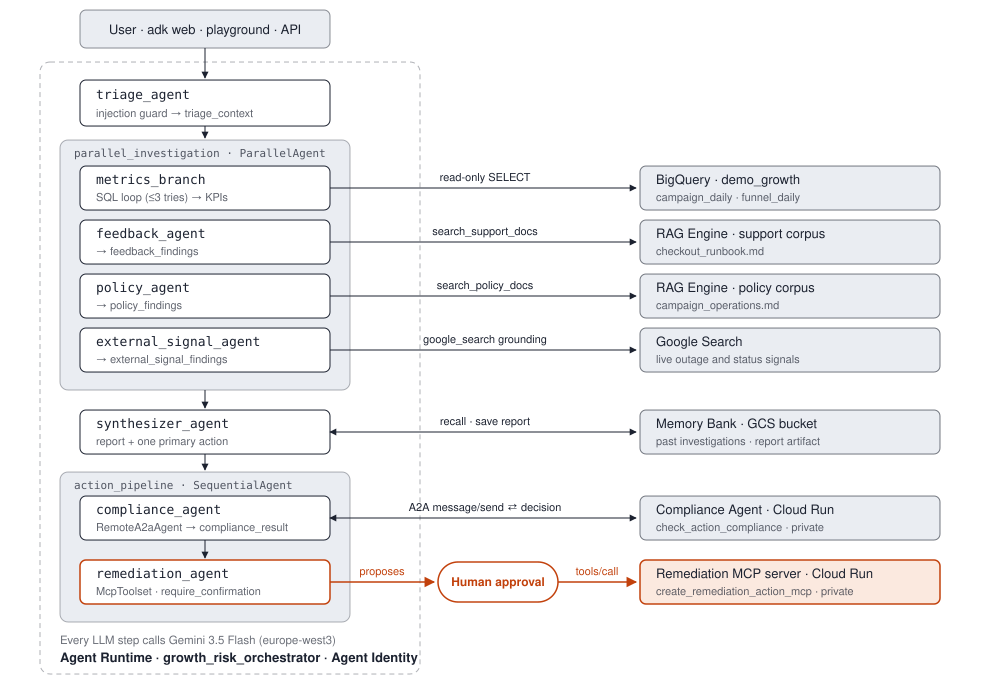

In [ ]:
from IPython.display import SVG
SVG(filename=REPO / "docs/architecture.svg")

Two independently deployed agents:

- **The orchestrator** (`growth-risk-agent`, on **Agent Runtime**). A pipeline of ADK agents: *triage* turns
  the request into structured fields; a *parallel investigation* queries BigQuery, two RAG corpora and Google
  Search at the same time; a *synthesizer* writes the report and picks **one** recommended action; the *action
  pipeline* asks the Compliance Agent and, if the action is allowed, proposes it as a ticket.
- **The Compliance Agent** (`compliance-agent`, on **Cloud Run**). Checks the action against policy and answers
  over the **A2A** (Agent2Agent) protocol. It is separate on purpose: the agent proposing an action can't change
  the rules it is judged by.

The only write in the whole system is the **MCP** tool `create_remediation_action_mcp`. ADK pauses before it runs
and waits for a human to approve.

## Check your tools and sign-in

Every tool below must print a version. `gcloud` must show your account and project.

In [ ]:
%%bash
gcloud --version | head -1; uv --version; terraform version | head -1; agents-cli --version 2>/dev/null | tail -1
echo; gcloud auth list --filter=status:ACTIVE --format="value(account)"; gcloud config get-value project

## Create the resources the agents depend on

The agents' own Terraform comes later (notebook 04). First come the things that exist *before* any agent:
data to investigate, documents to search, a tool to call, and an identity to call it with. The scripts in
[`setup/`](../setup/) create them; each one is safe to re-run. Open a script to see the exact `gcloud`
commands; the cells below explain what each one does.

### Step 1: APIs, the state bucket and the caller identity

- `gcloud services enable …` turns on the APIs the setup and the agents need.
- `gcloud storage buckets create gs://PROJECT-terraform-state` creates a versioned bucket for **Terraform state**:
  the record of what Terraform created. Terraform can't create its own backend, so this is done by hand once.
- `gcloud iam service-accounts create growth-risk-mcp-caller` creates the **caller service account**. Both remote
  services are private Cloud Run services that only accept an ID token for a principal with `roles/run.invoker`.
  The orchestrator impersonates this account to get those tokens, and step 1 lets *you* impersonate it too, so the
  agent behaves the same on your machine.

In [ ]:
%%bash
"$REPO/setup/01_project.sh"

### Step 2: demo data in BigQuery

`bq mk` creates the `demo_growth` dataset and `bq load` loads three small CSV files from
[`data/bigquery/`](../data/bigquery/). The data is synthetic: campaign `CAMP-2025-042` loses conversions on
2025-06-26, and the funnel shows why.

In [ ]:
%%bash
"$REPO/setup/02_bigquery.sh"

### Step 3: two RAG Engine corpora

RAG Engine does managed chunking, embedding and vector search. The script creates two corpora (policies and
support runbooks), each from the Markdown files in [`data/`](../data/), with the `text-embedding-005` model.

> **Cost:** a new project's RAG Engine runs on the *Basic* tier, which is billed while provisioned, even when
> idle. Notebook 99 switches it off.

In [ ]:
%%bash
cd "$REPO" && uv run -q setup/03_rag_corpora.py

### Step 4: the remediation MCP server

`gcloud run deploy --source mcp-server --no-allow-unauthenticated` builds the server's container with Cloud Build
and deploys it as a **private** Cloud Run service; `add-iam-policy-binding` lets only the caller service account
invoke it. This takes a few minutes.

In [ ]:
%%bash
"$REPO/setup/04_mcp_server.sh"

### Step 5: write your values into the config files

The repo ships with `YOUR_*` placeholders. This fills them in: a `terraform.tfvars` per Terraform stack (Terraform
loads it automatically, which `agents-cli infra` relies on), the Terraform backends, and a `.env` file per agent
for running locally.

In [ ]:
%%bash
cd "$REPO" && uv run -q setup/05_write_config.py

In [ ]:
%%bash
cat "$REPO/growth-risk-agent/.env" | grep -v "^#" | grep .

Next: [01 · Scaffold and code tour](01_scaffold_and_code_tour.ipynb).